# Exercise 45 – Fitting a Gaussian: which parameters, which starting point?

**Week 8 · Automatic differentiation**

A Gaussian $y = A\,e^{-(x-x_0)^2/2\sigma^2}$ is fitted to ten noisy points.

1. Fit only the amplitude $A$ for two fixed choices of $x_0$ and $\sigma$.
2. Fit all three parameters.
3. Repeat the full fit from several starting guesses – the loss landscape has
   more than one minimum, so the result depends on where we start.

In [1]:
import matplotlib.pyplot as plt
import torch
from torch import nn

from comphy.plotting import annotate, setup_axes
from comphy.training import fit

data = torch.tensor([[-1.493, 0.048], [-1.250, 0.459], [-0.842, 0.731],
                     [-0.676, 0.269], [-0.332, 0.004], [0.544, 0.000],
                     [1.363, 0.079], [1.621, 0.083], [1.853, 0.021],
                     [2.892, 0.000]])
x_data, y_data = data[:, 0], data[:, 1]
xs = torch.linspace(-2, 4, 300)


class Gaussian(nn.Module):
    def __init__(self, A=1.0, x0=-1.0, sigma=0.3):
        super().__init__()
        self.A = nn.Parameter(torch.tensor(A))
        self.x0 = nn.Parameter(torch.tensor(x0))
        self.sigma = nn.Parameter(torch.tensor(sigma))

    def forward(self, x):
        return self.A * torch.exp(-((x - self.x0) ** 2) / (2 * self.sigma**2))

    def label(self):
        return f"A = {self.A.item():.2f}, $x_0$ = {self.x0.item():.2f}, $\\sigma$ = {self.sigma.item():.2f}"


def plot_data(ax):
    ax.plot(x_data, y_data, "o", color="lightblue", markeredgecolor="C0", markersize=8)

## 1. Fitting only the amplitude

Passing `params=[model.A]` keeps $x_0$ and $\sigma$ fixed.

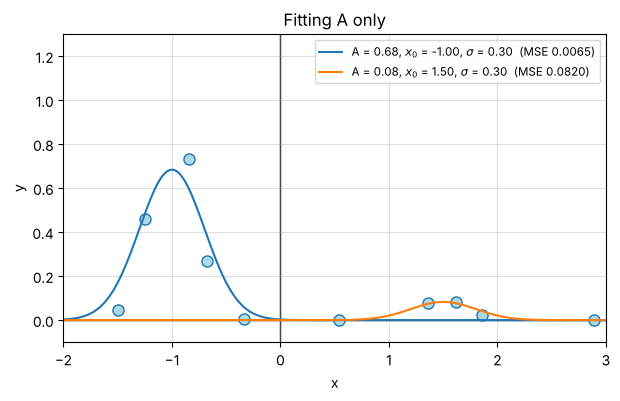

In [2]:
fig, ax = plt.subplots(figsize=(7, 4))
plot_data(ax)
for x0 in [-1.0, 1.5]:
    model = Gaussian(x0=x0, sigma=0.3)
    loss = fit(model, x_data, y_data, steps=2000, params=[model.A])[-1]
    with torch.no_grad():
        ax.plot(xs, model(xs), label=f"{model.label()}  (MSE {loss:.4f})")
setup_axes(ax, xlim=(-2, 3), ylim=(-0.1, 1.3), ylabel="y", title="Fitting A only")
ax.legend(fontsize="small")
plt.show()

With $x_0 = 1.5$ the Gaussian can only describe the small bump around
$x \approx 1.6$, so the best amplitude is small ($A \approx 0.08$).

## 2. Fitting all parameters

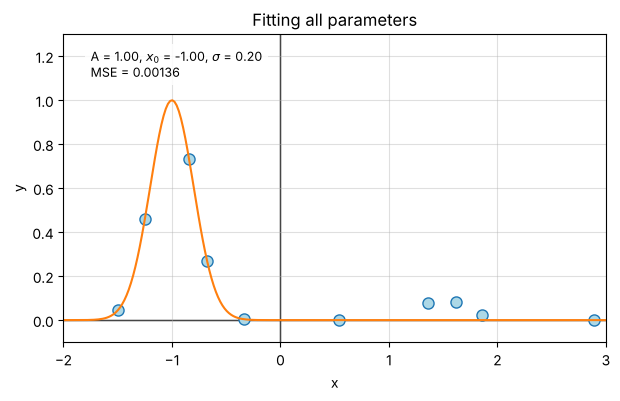

In [3]:
model = Gaussian()
loss = fit(model, x_data, y_data, steps=2000)[-1]

fig, ax = plt.subplots(figsize=(7, 4))
plot_data(ax)
with torch.no_grad():
    ax.plot(xs, model(xs), color="C1")
annotate(ax, f"{model.label()}\nMSE = {loss:.5f}")
setup_axes(ax, xlim=(-2, 3), ylim=(-0.1, 1.3), ylabel="y", title="Fitting all parameters")
plt.show()

## 3. Different starting guesses

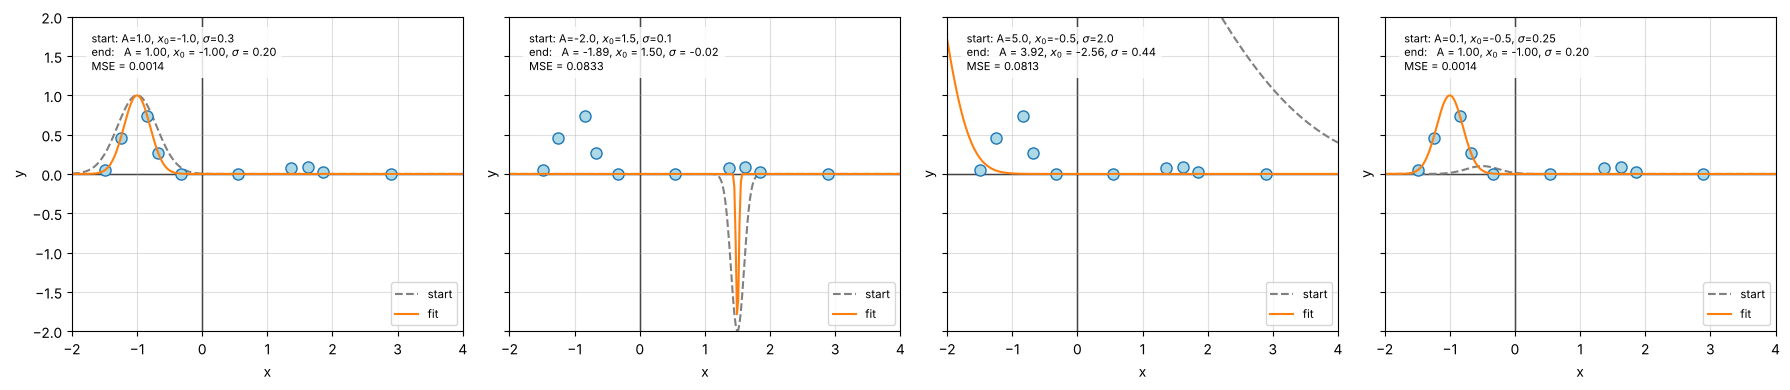

In [4]:
starts = [dict(A=1.0, x0=-1.0, sigma=0.3), dict(A=-2.0, x0=1.5, sigma=0.1),
          dict(A=5.0, x0=-0.5, sigma=2.0), dict(A=0.1, x0=-0.5, sigma=0.25)]

fig, axes = plt.subplots(1, len(starts), figsize=(18, 4), sharey=True)
for ax, start in zip(axes, starts):
    model = Gaussian(**start)
    with torch.no_grad():
        ax.plot(xs, model(xs), "--", color="gray", label="start")
    loss = fit(model, x_data, y_data, steps=2000)[-1]
    plot_data(ax)
    with torch.no_grad():
        ax.plot(xs, model(xs), color="C1", label="fit")
    annotate(ax, f"start: A={start['A']}, $x_0$={start['x0']}, $\\sigma$={start['sigma']}\n"
                 f"end:   {model.label()}\nMSE = {loss:.4f}", fontsize=8)
    setup_axes(ax, xlim=(-2, 4), ylim=(-2, 2), ylabel="y")
    ax.legend(loc="lower right", fontsize="small")
fig.tight_layout()
plt.show()

Starting guesses near the main peak converge to the same solution
($A \approx 1$, $x_0 \approx -1$, $\sigma \approx 0.2$). Starting far from it the
fit ends in a different local minimum: a narrow negative spike stays stuck at
$x_0 = 1.5$, and a broad Gaussian slides off to the left of the data.